# Phishing URL Detection with Random Forest (Stage 1)

Lexical-feature Random Forest for the stage-1 task of the IFLP-ICDSOS 2026 paper *A Comparative Analysis of Machine Learning Algorithms for Job Phishing Detection*: classify a URL as **phishing** or **legitimate**. Stage 2 (clustering of flagged URLs into job and non-job themes) uses only the best stage-1 model and is not part of this notebook.

**Data (v3).** Legitimate URLs from the Tranco list, phishing URLs from PhishTank (verified, online-valid). Training set collected 19 Sep 2026 (79,998 URLs, 50:50); test set collected 28 Oct 2026 (38,387 URLs after removing URLs already in the training set, 61.8% phishing). The test set is therefore **temporally separated**, not a random split.

**Pipeline:** data audit → feature set FS-24 → shared site-grouped cross-validation on the training set → (optional) tuning → single evaluation on the test set, overall and split by whether the URL's site was seen in training → feature importance (impurity-based and permutation-based).

Design choices that matter for a publishable result:

1. **Site-grouped validation.** Phishing URLs reuse the same platforms (QR-code services, link shorteners, site builders). Rows from the same registered domain are not independent, so the folds in `data/cv_folds.csv` keep each site in one fold. All five models in the paper use this one fold file.
2. **Seen-site vs unseen-site test results.** About half of the test URLs come from sites that also occur in the training set. The score on unseen sites is the better estimate for URLs from new domains.
3. **Two importance measures.** Mean Decrease in Impurity (MDI) is biased toward continuous, high-cardinality features [1]; permutation importance on the test set is reported beside it.

The test set is used once, after all modelling decisions are fixed.

## 1. Setup

In [1]:
import hashlib
import io
import re
import urllib.request
import warnings
from pathlib import Path
from urllib.parse import urlsplit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, classification_report,
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42                 # single seed for every stochastic component
N_SPLITS = 5              # folds in data/cv_folds.csv
RUN_TUNING = False        # True runs the randomized hyperparameter search (section 8)
REGENERATE_FOLDS = False  # True only to rebuild data/cv_folds.csv; all models must share one fold file
PERM_REPEATS = 10         # permutation-importance repeats on the test set
MODEL_NAME = "RandomForest"

# Data source. Local files take priority (e.g. uploaded to the Colab session);
# otherwise the files are downloaded from DATA_BASE_URL.
DATA_BASE_URL = "https://raw.githubusercontent.com/fizzz96/phishing-url-rf/main/data"
DATA_FILES = {
    # filename: expected SHA-256 (guarantees every run uses the identical dataset)
    "train_features.csv": "4dfb71b28307b9ab34fb19e0595a222031c43b5c8a1dea3bad47ead02fa6a35d",
    "test_features.csv":  "c59cd8e238db5b534b48e7fbce7532a9d6d233949efa2e915d1b49f328ea373e",
    "cv_folds.csv":       "7f8a1b8865806c29ad8d01c3882c5bdfedd32c166012366d5d13e5c4c4242f2d",
}
TARGET = "ClassLabel"     # 1 = phishing, 0 = legitimate
ID_COL = "URL"

# FS-24: all 24 lexical features, used by the tree-based models (RF, LightGBM, XGBoost).
# LR and SVM use FS-20, which drops has_http, tokencount, count_letters, numberofdigits (see README).
FEATURES = [
    "urllength", "hasipaddress", "dotcount", "httpsflag", "urlentropy", "tokencount",
    "subdomaincount", "queryparamcount", "tldlength", "pathlength", "hash",
    "hyphenindomain", "numberofdigits", "tldpopularity", "suspiciousfileextension",
    "domainnamelength", "percentagenumericchars", "has_http", "count_dashes",
    "count_underscores", "count_slashes", "count_ques", "count_non_alphanumeric", "count_letters",
]

np.random.seed(SEED)
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight"})

## 2. Load data

Files are read from the working directory if present, otherwise downloaded from `DATA_BASE_URL`, so the notebook runs for anyone without manual uploads. A SHA-256 check confirms every run uses byte-identical data. The schema check fails early if a column is missing or renamed.

In [2]:
def load_split(filename: str) -> pd.DataFrame:
    # Read local copy if present, else download; verify SHA-256 either way.
    local = Path(filename)
    if local.exists():
        raw, source = local.read_bytes(), str(local)
    else:
        source = f"{DATA_BASE_URL.rstrip('/')}/{filename}"
        with urllib.request.urlopen(source, timeout=120) as resp:
            raw = resp.read()
    digest = hashlib.sha256(raw).hexdigest()
    expected = DATA_FILES[filename]
    if digest != expected:
        raise ValueError(f"{filename}: SHA-256 mismatch (got {digest[:12]}..., expected {expected[:12]}...). "
                         "The file differs from the version used in the paper.")
    print(f"Loaded {filename} from {source} (SHA-256 verified)")
    return pd.read_csv(io.BytesIO(raw))

train_df = load_split("train_features.csv")
test_df = load_split("test_features.csv")

expected = [ID_COL, TARGET] + FEATURES
for name, df in [("train", train_df), ("test", test_df)]:
    missing_cols = set(expected) - set(df.columns)
    assert not missing_cols, f"{name}: missing columns {missing_cols}"

print(f"Train: {train_df.shape[0]:,} rows x {train_df.shape[1]} cols")
print(f"Test : {test_df.shape[0]:,} rows x {test_df.shape[1]} cols")
train_df.head()

Loaded train_features.csv from train_features.csv (SHA-256 verified)


Loaded test_features.csv from test_features.csv (SHA-256 verified)
Train: 79,998 rows x 26 cols
Test : 38,387 rows x 26 cols


,URL,ClassLabel,urllength,hasipaddress,dotcount,httpsflag,urlentropy,tokencount,subdomaincount,queryparamcount,...,suspiciousfileextension,domainnamelength,percentagenumericchars,has_http,count_dashes,count_underscores,count_slashes,count_ques,count_non_alphanumeric,count_letters
0,https://avanzapich1ncha.webcindario.com/,1,40,0,2,1,4.156198,4,1,0,...,0,11,2.500000,0,0,0,3,0,6,33
1,https://newtail.com.br,0,22,0,2,1,4.061482,4,1,0,...,0,3,0.000000,0,0,0,2,0,5,17
2,https://inform.kz,0,17,0,1,1,3.852169,3,0,0,...,0,6,0.000000,0,0,0,2,0,4,13
3,https://winpreisu12.web.app/,1,28,0,2,1,3.923252,4,1,0,...,0,3,7.142857,0,0,0,3,0,6,20
4,https://chatbot.page/Ob0RSF,1,27,0,1,1,3.986188,4,0,0,...,0,7,3.703704,0,0,0,3,0,5,21


## 3. Data audit

Checks performed before any modelling:

- missing values and class balance in each split;
- zero-variance features;
- duplicates and train–test overlap at three levels: exact URL, normalised URL (scheme, `www.`, trailing slash and case removed), and **site** (registered domain). Site overlap is the relevant leakage measure for URL classifiers, because a model can score well by recognising a platform it has already seen;
- highly correlated feature pairs (|Pearson r| > 0.8, the rule used in the paper), which split importance between them.

The audit reports these quantities; it does not remove rows, so the data stay identical to the sets described in the paper.

In [3]:
try:
    import tldextract
except ImportError:                    # not preinstalled on Colab
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tldextract"], check=True)
    import tldextract
_ext = tldextract.TLDExtract(suffix_list_urls=())   # bundled Public Suffix List snapshot, no network call

def host_of(url: str) -> str:
    # Hostname without a leading "www."; handles URLs without a scheme and malformed hosts.
    u = url if "://" in url else "http://" + url
    try:
        host = (urlsplit(u).hostname or "").lower()
    except ValueError:
        host = ""
    return host[4:] if host.startswith("www.") else host

def site_of(host: str) -> str:
    # Registered domain, e.g. "indeed.com" for both "www.indeed.com" and "id.indeed.com".
    r = _ext(host)
    dom = r.top_domain_under_public_suffix if hasattr(r, "top_domain_under_public_suffix") else r.registered_domain
    return dom or host                                    # IP addresses fall back to the host

def norm_url(u: str) -> str:
    s = re.sub(r"^[a-z][a-z0-9+.\-]*://", "", str(u).strip().lower())
    return re.sub(r"^www\d*\.", "", s).rstrip("/")

for df in (train_df, test_df):
    df["host"] = df[ID_COL].astype(str).map(host_of)
    df["site"] = df["host"].map(site_of)

na_total = int(train_df[FEATURES + [TARGET]].isna().sum().sum() + test_df[FEATURES + [TARGET]].isna().sum().sum())
print("Missing values (train + test):", na_total)

balance = pd.DataFrame({
    "train_n": train_df[TARGET].value_counts(),
    "train_%": train_df[TARGET].value_counts(normalize=True).mul(100).round(2),
    "test_n": test_df[TARGET].value_counts(),
    "test_%": test_df[TARGET].value_counts(normalize=True).mul(100).round(2),
}).rename(index={0: "legitimate", 1: "phishing"})
print("\nClass balance:"); print(balance)

constant = [c for c in FEATURES if train_df[c].nunique(dropna=False) <= 1]
print("\nZero-variance features in train:", constant or "none")

tr_norm, te_norm = train_df[ID_COL].map(norm_url), test_df[ID_COL].map(norm_url)
print("\nDuplicate URLs, exact      - train:", train_df[ID_COL].duplicated().sum(), "| test:", test_df[ID_COL].duplicated().sum())
print("Duplicate URLs, normalised - train:", tr_norm.duplicated().sum(), "| test:", te_norm.duplicated().sum())
print("Train-test overlap, exact URL:", len(set(train_df[ID_COL]) & set(test_df[ID_COL])),
      "| normalised URL:", len(set(tr_norm) & set(te_norm)))

train_sites = set(train_df["site"])
test_df["site_seen"] = test_df["site"].isin(train_sites)
seen = (test_df.groupby(TARGET)["site_seen"].agg(["sum", "size", "mean"])
        .rename(index={0: "legitimate", 1: "phishing"}).rename(columns={"sum": "seen", "size": "n", "mean": "share"}))
seen["share"] = (seen["share"] * 100).round(2)
print(f"\nSites in train: {len(train_sites):,}")
print("Test URLs whose site also occurs in train:"); print(seen)
print(f"Overall: {test_df['site_seen'].mean():.2%}")

top_sites = (train_df[train_df[TARGET] == 1]["site"].value_counts(normalize=True).head(10).mul(100).round(2)
             .rename("% of phishing train"))
print("\nTen most frequent sites among phishing training URLs:"); print(top_sites)

r = train_df[[c for c in FEATURES if c not in constant]].corr(method="pearson")
pairs = (r.where(np.triu(np.ones(r.shape, dtype=bool), k=1)).stack()
         .loc[lambda s: s.abs() > 0.8].sort_values(key=np.abs, ascending=False).round(3))
print("\nFeature pairs with |Pearson r| > 0.8:")
print(pairs.to_string() if len(pairs) else "  none")

Missing values (train + test): 0

Class balance:
            train_n  train_%  test_n  test_%
ClassLabel                                  
phishing      39999     50.0   23729   61.82
legitimate    39999     50.0   14658   38.18

Zero-variance features in train: none



Duplicate URLs, exact      - train: 0 | test: 0
Duplicate URLs, normalised - train: 1042 | test: 259
Train-test overlap, exact URL: 0 | normalised URL: 717

Sites in train: 48,782
Test URLs whose site also occurs in train:
             seen      n  share
ClassLabel                     
legitimate    132  14658   0.90
phishing    19234  23729  81.06
Overall: 50.45%



Ten most frequent sites among phishing training URLs:
site
qrco.de            6.29
weebly.com         6.27
q-r.to             4.95
google.com         4.73
ead.me             4.57
wixstudio.com      3.79
pages.dev          3.54
web.app            2.72
firebaseapp.com    2.70
bit.ly             2.52
Name: % of phishing train, dtype: float64

Feature pairs with |Pearson r| > 0.8:
httpsflag       has_http                 -1.000
urllength       count_letters             0.997
                numberofdigits            0.949
tokencount      count_non_alphanumeric    0.927
numberofdigits  count_letters             0.926


## 4. Feature set

The team uses two feature sets (paper, section 2.3.5):

- **FS-24** (all 24 features) for the tree-based models: RF, LightGBM, XGBoost. Tree splits use one feature at a time, so correlated features do not destabilise the model the way they destabilise regression coefficients.
- **FS-20** for logistic regression and SVM: FS-24 without `has_http`, `tokencount`, `count_letters`, `numberofdigits`.

This notebook uses FS-24. Zero-variance features would be dropped here; on this dataset there are none. Median imputation is fitted on the training set only and is a no-op when nothing is missing. No scaling is applied, because tree splits are invariant to monotonic transformations.

In [4]:
features = [c for c in FEATURES if c not in constant]

train_medians = train_df[features].median()
train_df[features] = train_df[features].fillna(train_medians)
test_df[features] = test_df[features].fillna(train_medians)

print(f"Dropped zero-variance: {constant or 'none'}")
print(f"Features used ({len(features)}): {features}")

Dropped zero-variance: none
Features used (24): ['urllength', 'hasipaddress', 'dotcount', 'httpsflag', 'urlentropy', 'tokencount', 'subdomaincount', 'queryparamcount', 'tldlength', 'pathlength', 'hash', 'hyphenindomain', 'numberofdigits', 'tldpopularity', 'suspiciousfileextension', 'domainnamelength', 'percentagenumericchars', 'has_http', 'count_dashes', 'count_underscores', 'count_slashes', 'count_ques', 'count_non_alphanumeric', 'count_letters']


## 5. Feature matrix and target

In [5]:
X_train, y_train = train_df[features], train_df[TARGET].astype(int)
X_test, y_test = test_df[features], test_df[TARGET].astype(int)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (79998, 24) | X_test: (38387, 24)


## 6. Shared cross-validation folds

All five classifiers in the comparison are evaluated on the **same** five folds, stored in `data/cv_folds.csv` (one row per training URL: `URL`, `host`, `site`, `fold`). Sharing the file, rather than letting each notebook call `StratifiedGroupKFold` itself, guarantees identical folds across scikit-learn versions and makes the per-fold scores of different models paired observations.

The folds were built once with `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`, grouped by **site** (registered domain via the Public Suffix List). Grouping by site keeps every URL of a shared platform such as `qrco.de` or `weebly.com` in one fold, so no fold is validated on a platform it was trained on. Set `REGENERATE_FOLDS = True` only if the training data change; the new file must then replace `data/cv_folds.csv` for every model.

In [6]:
if REGENERATE_FOLDS:
    sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    fold_id = np.empty(len(X_train), dtype=int)
    for k, (_, val_idx) in enumerate(sgkf.split(X_train, y_train, train_df["site"])):
        fold_id[val_idx] = k
    folds_df = pd.DataFrame({ID_COL: train_df[ID_COL], "host": train_df["host"],
                             "site": train_df["site"], "fold": fold_id})
    folds_df.to_csv("cv_folds.csv", index=False)
    print("New cv_folds.csv written. SHA-256:", hashlib.sha256(Path("cv_folds.csv").read_bytes()).hexdigest())
else:
    folds_df = load_split("cv_folds.csv")

# Align folds to the row order of X_train by URL and check integrity
fold_map = folds_df.set_index(ID_COL)["fold"]
assert set(fold_map.index) == set(train_df[ID_COL]), "cv_folds.csv does not match the training URLs"
fold_id = train_df[ID_COL].map(fold_map).to_numpy()
assert folds_df.groupby("site")["fold"].nunique().max() == 1, "a site appears in more than one fold"

cv_splits = [(np.flatnonzero(fold_id != k), np.flatnonzero(fold_id == k)) for k in range(N_SPLITS)]

site_map = folds_df.set_index(ID_COL)["site"]
fold_frame = pd.DataFrame({"fold": fold_id, "y": y_train.to_numpy(),
                           "site": train_df[ID_COL].map(site_map).to_numpy()})
fold_table = fold_frame.groupby("fold").agg(
    n=("y", "size"),
    phishing_pct=("y", lambda v: round(100 * v.mean(), 1)),
    sites=("site", "nunique"),
)
fold_table

Loaded cv_folds.csv from cv_folds.csv (SHA-256 verified)


,n,phishing_pct,sites
fold,,,
0,16001,50.0,9771
1,15999,50.0,9750
2,15999,50.0,9749
3,16000,50.0,9755
4,15999,50.0,9757


## 7. Model and cross-validated performance

Random Forest configuration:

- `n_estimators=500`: enough trees for stable votes and importance estimates; adding trees does not cause overfitting, it only costs compute.
- `max_features="sqrt"`: ⌊√24⌋ = 4 candidate features per split, the standard decorrelation setting for classification [2].
- `class_weight=None`: the training set is balanced (50:50).
- `random_state=SEED`, `n_jobs=-1`.

Per-fold scores are written to `cv_scores_<model>.csv` in the long format shared by all models (`model`, `fold`, `metric`, `value`), so the five files can be concatenated directly for the comparison table and paired tests.

In [7]:
rf = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight=None,
    random_state=SEED,
    n_jobs=-1,
)

scoring = {
    "accuracy": "accuracy", "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc", "mcc": "matthews_corrcoef",
}
cv_res = cross_validate(rf, X_train, y_train, cv=cv_splits, scoring=scoring, n_jobs=1)

cv_scores = (pd.DataFrame({m: cv_res[f"test_{m}"] for m in scoring})
             .rename_axis("fold").reset_index()
             .melt(id_vars="fold", var_name="metric", value_name="value"))
cv_scores.insert(0, "model", MODEL_NAME)
scores_path = f"cv_scores_{MODEL_NAME.lower()}.csv"
cv_scores.to_csv(scores_path, index=False)

cv_summary = (cv_scores.groupby("metric", sort=False)["value"]
              .agg(mean="mean", sd=lambda v: v.std(ddof=1)).round(4))
print(f"{N_SPLITS}-fold site-grouped CV on the training set; per-fold scores saved to {scores_path}")
print(cv_summary)
print("\nPer fold:")
print(cv_scores.pivot(index="fold", columns="metric", values="value")[list(scoring)].round(4))

5-fold site-grouped CV on the training set; per-fold scores saved to cv_scores_randomforest.csv
             mean      sd
metric                   
accuracy   0.9788  0.0008
precision  0.9795  0.0007
recall     0.9780  0.0015
f1         0.9787  0.0008
roc_auc    0.9950  0.0010
mcc        0.9575  0.0016

Per fold:
metric  accuracy  precision  recall      f1  roc_auc     mcc
fold                                                        
0         0.9793     0.9800  0.9786  0.9793   0.9952  0.9586
1         0.9779     0.9784  0.9775  0.9779   0.9948  0.9559
2         0.9797     0.9796  0.9799  0.9798   0.9961  0.9595
3         0.9789     0.9794  0.9784  0.9789   0.9954  0.9578
4         0.9779     0.9800  0.9758  0.9779   0.9935  0.9559


## 8. Hyperparameter tuning (optional)

Randomized search over the parameters that most affect RF bias–variance, on the shared folds from section 6, optimised for F1 on the phishing class. Set `RUN_TUNING = True` in section 1 to run it (40 configurations × 5 folds; slow on 80k rows). Report the CV score of the best configuration, not the test score, as the basis for selection.

In [8]:
if RUN_TUNING:
    param_dist = {
        "n_estimators": [300, 500, 800],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2", 0.5],
        "class_weight": [None, "balanced"],
    }
    search = RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        param_distributions=param_dist, n_iter=40, scoring="f1",
        cv=cv_splits, random_state=SEED, n_jobs=1, refit=True,
    )
    search.fit(X_train, y_train)
    print("Best params:", search.best_params_)
    print(f"Best site-grouped CV F1: {search.best_score_:.4f}")
    rf = search.best_estimator_      # replaces the default model for sections 9-11
else:
    print("Tuning skipped (RUN_TUNING = False); using the default configuration.")

Tuning skipped (RUN_TUNING = False); using the default configuration.


## 9. Final training and test-set evaluation

The model is fitted on the full training set and evaluated once on the test set (threshold 0.5, phishing as the positive class). Results are reported for three subsets:

- **all test URLs**;
- **seen site**: the URL's registered domain also occurs in the training set;
- **unseen site**: the registered domain is new. This subset is the better estimate of performance on URLs from new domains.

Metrics: accuracy, precision, recall, F1, **MCC** (uses all four confusion-matrix cells and stays informative under class imbalance [3]), ROC-AUC and PR-AUC. For the full test set, 95% percentile-bootstrap intervals (1,000 resamples) are added. Rows from one site are not independent, so these row-level intervals are narrower than the true uncertainty and should be read as indicative.

In [9]:
if not RUN_TUNING:          # RandomizedSearchCV(refit=True) has already fitted the tuned model
    rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Phishing (1)"], digits=4))

metric_fns = {
    "Accuracy":  lambda y, p, s: accuracy_score(y, p),
    "Precision": lambda y, p, s: precision_score(y, p, zero_division=0),
    "Recall":    lambda y, p, s: recall_score(y, p),
    "F1":        lambda y, p, s: f1_score(y, p),
    "MCC":       lambda y, p, s: matthews_corrcoef(y, p),
    "ROC-AUC":   lambda y, p, s: roc_auc_score(y, s),
    "PR-AUC":    lambda y, p, s: average_precision_score(y, s),
}

def bootstrap_ci(y, p, s, fn, n_boot=1000, alpha=0.05, seed=SEED):
    # Percentile bootstrap; resamples with a single class are skipped.
    rng = np.random.default_rng(seed)
    y, p, s = np.asarray(y), np.asarray(p), np.asarray(s)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        stats.append(fn(y[idx], p[idx], s[idx]))
    return np.quantile(stats, [alpha / 2, 1 - alpha / 2])

seen_mask = test_df["site_seen"].to_numpy()
rows = []
for subset, mask in [("all", np.ones(len(y_test), bool)), ("seen site", seen_mask), ("unseen site", ~seen_mask)]:
    yt, yp, ys = y_test.to_numpy()[mask], y_pred[mask], y_proba[mask]
    tn, fp, fn_, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    for name, fn in metric_fns.items():
        row = {"subset": subset, "n": int(mask.sum()), "n_legit": int(tn + fp), "metric": name, "value": fn(yt, yp, ys)}
        if subset == "all":
            row["ci95_low"], row["ci95_high"] = bootstrap_ci(yt, yp, ys, fn)
        rows.append(row)
test_metrics = pd.DataFrame(rows)
test_metrics.insert(0, "model", MODEL_NAME)
test_metrics.to_csv(f"test_metrics_{MODEL_NAME.lower()}.csv", index=False)

print("Test-set metrics (95% bootstrap CI for the full test set):")
test_metrics.pivot_table(index="metric", columns="subset", values="value", sort=False)[["all", "seen site", "unseen site"]].round(4)

                precision    recall  f1-score   support

Legitimate (0)     0.9648    0.9473    0.9559     14658
  Phishing (1)     0.9678    0.9786    0.9732     23729

      accuracy                         0.9667     38387
     macro avg     0.9663    0.9629    0.9646     38387
  weighted avg     0.9666    0.9667    0.9666     38387



Test-set metrics (95% bootstrap CI for the full test set):


subset,all,seen site,unseen site
metric,,,
Accuracy,0.9667,0.9933,0.9395
Precision,0.9678,0.9979,0.8476
Recall,0.9786,0.9953,0.9072
F1,0.9732,0.9966,0.8764
MCC,0.9292,0.5903,0.8373
ROC-AUC,0.9929,0.9812,0.9716
PR-AUC,0.9957,0.9998,0.9459


In [10]:
test_metrics[test_metrics["subset"] == "all"][["metric", "value", "ci95_low", "ci95_high"]].set_index("metric").round(4)

,value,ci95_low,ci95_high
metric,,,
Accuracy,0.9667,0.9649,0.9684
Precision,0.9678,0.9656,0.9700
Recall,0.9786,0.9768,0.9804
F1,0.9732,0.9717,0.9746
MCC,0.9292,0.9253,0.9329
ROC-AUC,0.9929,0.9922,0.9936
PR-AUC,0.9957,0.9953,0.9962


## 10. Confusion matrix

Counts with row-normalised percentages. The row percentage in the phishing row is the recall (detection rate); the off-diagonal cell in that row is the miss rate, the costlier error in a security setting.

TN=13885  FP=773  FN=507  TP=23222
False positive rate = 0.0527 | False negative rate = 0.0214


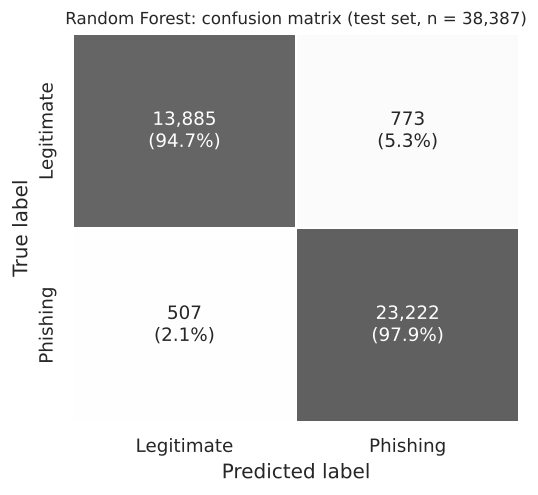

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = ["Legitimate", "Phishing"]
annot = np.array([[f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"False positive rate = {fp / (fp + tn):.4f} | False negative rate = {fn / (fn + tp):.4f}")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Greys", vmin=0, vmax=140, cbar=False,
            xticklabels=labels, yticklabels=labels, linewidths=1, linecolor="white",
            annot_kws={"size": 11}, ax=ax)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(f"Random Forest: confusion matrix (test set, n = {len(y_test):,})", fontsize=10)
plt.savefig("fig_confusion_matrix.png")
plt.show()

## 11. Feature importance

Two measures are computed:

- **MDI (impurity-based)**: `feature_importances_`, the total Gini decrease attributable to each feature, averaged over trees. Computed on training data; inflated for continuous features with many distinct split points and for features correlated with each other.
- **Permutation importance**: drop in test-set ROC-AUC when one feature's values are shuffled (`PERM_REPEATS` repeats). Measured on unseen data and tied directly to predictive performance. Error bars show ± 1 SD across repeats.

When the two rankings disagree, report the permutation ranking. Correlated features share importance under permutation: shuffling one leaves its information available through the others, so each can look less important than the group is; unrestricted permutation also forces the model to extrapolate to unrealistic feature combinations [4]. FS-24 contains exact or near duplicates (`has_http` = 1 − `httpsflag`; `urllength` ≈ `count_letters`), so this matters here.

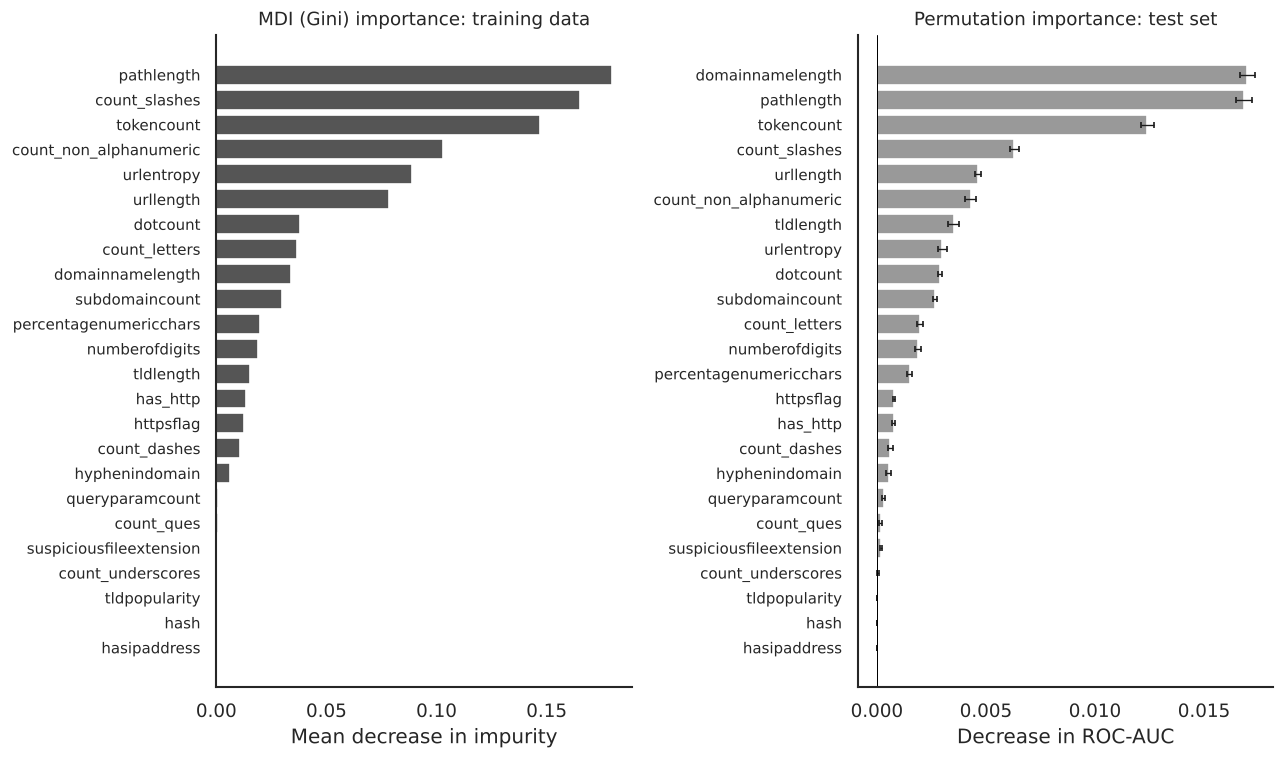

,MDI,perm_mean,perm_sd,MDI_rank,perm_rank
domainnamelength,0.0339,0.0170,0.0003,9,1
pathlength,0.1798,0.0168,0.0004,1,2
tokencount,0.1471,0.0124,0.0003,3,3
count_slashes,0.1651,0.0063,0.0002,2,4
urllength,0.0786,0.0046,0.0001,6,5
count_non_alphanumeric,0.1028,0.0043,0.0003,4,6
tldlength,0.0153,0.0035,0.0003,13,7
urlentropy,0.0891,0.0030,0.0002,5,8
dotcount,0.0378,0.0029,0.0001,7,9
subdomaincount,0.0298,0.0027,0.0001,10,10


In [12]:
mdi = pd.Series(rf.feature_importances_, index=features, name="MDI")

perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=PERM_REPEATS, random_state=SEED, n_jobs=1)
perm_df = pd.DataFrame({"perm_mean": perm.importances_mean, "perm_sd": perm.importances_std},
                       index=features)

importance = pd.concat([mdi, perm_df], axis=1)
importance["MDI_rank"] = importance["MDI"].rank(ascending=False, method="min").astype(int)
importance["perm_rank"] = importance["perm_mean"].rank(ascending=False, method="min").astype(int)
importance = importance.sort_values("perm_mean", ascending=False)
importance.rename_axis("feature").to_csv(f"feature_importance_{MODEL_NAME.lower()}.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharey=False)
mdi_sorted = importance["MDI"].sort_values()
axes[0].barh(mdi_sorted.index, mdi_sorted.values, color="#555555")
axes[0].set_title("MDI (Gini) importance: training data", fontsize=11)
axes[0].set_xlabel("Mean decrease in impurity")

perm_sorted = importance.sort_values("perm_mean")
axes[1].barh(perm_sorted.index, perm_sorted["perm_mean"], xerr=perm_sorted["perm_sd"],
             color="#999999", error_kw={"elinewidth": 0.8, "capsize": 2})
axes[1].axvline(0, color="black", lw=0.6)
axes[1].set_title("Permutation importance: test set", fontsize=11)
axes[1].set_xlabel("Decrease in ROC-AUC")

for ax in axes:
    ax.tick_params(axis="y", labelsize=9)
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("fig_feature_importance.png")
plt.show()

importance.round(4)

### Direction of effect

Importance says *how much* a feature matters, not *which way*. The class-conditional medians and means below give the direction. For a model-based view of direction, use SHAP or partial-dependence plots.

In [13]:
top = importance.index[:8]
direction = (train_df.groupby(TARGET)[list(top)].median().T
             .rename(columns={0: "median_legit", 1: "median_phish"}))
direction["mean_legit"] = train_df.loc[y_train == 0, top].mean()
direction["mean_phish"] = train_df.loc[y_train == 1, top].mean()
direction.round(3)

ClassLabel,median_legit,median_phish,mean_legit,mean_phish
domainnamelength,7.000,6.000,7.893,7.320
pathlength,0.000,7.000,0.144,11.554
tokencount,3.000,5.000,3.220,6.249
count_slashes,2.000,3.000,2.079,3.355
urllength,20.000,38.000,20.598,48.248
count_non_alphanumeric,4.000,7.000,4.294,7.823
tldlength,3.000,3.000,2.764,2.852
urlentropy,3.703,4.152,3.695,4.256


## 12. Interpreting the results

*Figures quoted below are from the reference run committed with this notebook (scikit-learn 1.9.1, `SEED = 42`, default configuration, FS-24). Small differences across library versions are expected; the folds themselves are fixed by `data/cv_folds.csv`.*

### 12.1 Cross-validation, test set, and the seen/unseen-site split

| Evaluation | n | Accuracy | F1 (phishing) | MCC | ROC-AUC |
|---|---|---|---|---|---|
| Site-grouped 5-fold CV on train (mean ± SD) | 79,998 | 0.979 ± 0.001 | 0.979 ± 0.001 | 0.958 ± 0.002 | 0.995 ± 0.001 |
| Test, all URLs | 38,387 | 0.967 | 0.973 | 0.929 | 0.993 |
| Test, site seen in training | 19,366 | 0.993 | 0.997 | 0.590 | 0.981 |
| Test, site not seen in training | 19,021 | 0.940 | 0.876 | 0.837 | 0.972 |

The CV estimate and the full test score agree within about one point of accuracy, which shows the model holds up across the 39-day gap between the two collections. The split by site is where the result needs care:

- 81.1% of phishing test URLs come from a site that also occurs in training (mostly shared platforms such as `qrco.de`, `weebly.com`, `google.com`), against 0.9% of legitimate test URLs. The "seen site" subset is therefore almost all phishing (132 legitimate URLs out of 19,366). Its F1 of 0.997 mostly reflects recognising platforms already seen, and its MCC of 0.590 rests on 132 legitimate rows.
- On sites never seen in training, F1 drops to 0.876 and precision to 0.848: about one in seven URLs flagged as phishing on a new site is legitimate. This is the better estimate for links from new domains.

For the paper: report the full test score together with the unseen-site score, and describe the seen-site subset as dominated by shared phishing platforms.

### 12.2 What the model relies on

- **Path structure dominates.** Permutation importance ranks `domainnamelength`, `pathlength` and `tokencount` first, followed by `count_slashes`; MDI ranks `pathlength`, `count_slashes` and `tokencount` highest. In training, 92.7% of legitimate URLs have no path (`pathlength = 0`) against 7.5% of phishing URLs, because legitimate URLs come from Tranco domain lists while phishing URLs point to specific pages.
- **A one-feature rule is a strong baseline.** Predicting "phishing" whenever `pathlength > 0` reaches F1 0.908 and MCC 0.749 on the test set. RF improves on this (F1 0.973, MCC 0.929), so it uses more than the path, but a large part of the separation is "homepage vs inner page". This is a property of how the legitimate class was collected and belongs in the limitations section, together with the recommendation to add legitimate URLs with deep paths.
- **Correlated features split importance.** `has_http` and `httpsflag` are exact complements (r = −1.00) and share almost identical, low importance. `urllength` and `count_letters` (r = 0.997) behave the same way. Permuting one member of such a pair leaves its information in the other, so neither looks important on its own [4].
- **Uninformative features.** `hash`, `hasipaddress`, `tldpopularity` and `suspiciousfileextension` have near-zero importance in both measures; they are rare in this corpus.

### References

[1] S. Nembrini, I. R. König, and M. N. Wright, "The revival of the Gini importance?," *Bioinformatics*, vol. 34, no. 21, pp. 3711–3718, 2018, doi: 10.1093/bioinformatics/bty373.

[2] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, 2001, doi: 10.1023/A:1010933404324.

[3] D. Chicco and G. Jurman, "The advantages of the Matthews correlation coefficient (MCC) over F1 score and accuracy in binary classification evaluation," *BMC Genomics*, vol. 21, art. no. 6, 2020, doi: 10.1186/s12864-019-6413-7.

[4] G. Hooker, L. Mentch, and S. Zhou, "Unrestricted permutation forces extrapolation: Variable importance requires at least one more model, or there is no free variable importance," *Stat. Comput.*, vol. 31, no. 6, art. no. 82, 2021.